# Synthetic city

Generates an invented city with the same columns as the Paris `df_osm`, `df_area` and `df_streets`
(see `benchmark_pipeline/loader/osm_loaders.py`): POI, street and area names do not exist, nor do the
cooking types. Categories stay the real ones, since the benchmark templates rely on them.
Everything is in EPSG:2154, so distances are in meters, as the templates expect.

In [1]:
import math
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
from shapely import affinity
from shapely.geometry import LineString, MultiPoint, Point, box
from shapely.ops import unary_union, voronoi_diagram
from shapely.prepared import prep

from benchmark_pipeline.config import FEATURES
from benchmark_pipeline.generator.template_question.ratio import allocate
from benchmark_pipeline.loader.data_cleaning.cooking_column import DIET, DISH, REGIONAL, VENUE
from benchmark_pipeline.loader.data_cleaning.serialize import serialize_poi

# Size of the city
N_POIS = 19000                       # POIs in df_osm
N_STREETS = 1700                      # streets in df_streets
N_AREAS = 100                       # areas in df_area: administrative areas, parks and gardens
WIDTH_M = 11000                      # width of the map, in meters
HEIGHT_M = 9000                     # height of the map, in meters
ORIGIN = (700_000.0, 6_600_000.0)   # south-west corner of the map, in Lambert-93 (EPSG:2154)
N_COOKING_TYPES = 40                # invented cooking types
CITY_NAME = None                    # invented when None
SEED = 0
OUTPUT_DIR = Path("data/synthetic_cities")

In [2]:
# Measured on the Paris df_osm (Gseek/demo_data/df_osm.parquet).
# Parks and gardens are not in CATEGORY_WEIGHTS: each green area of df_area gets its own POI.
CATEGORY_WEIGHTS = {"restaurant": 10124, "cafe": 2733, "bar": 1895, "hotel": 1885,
                    "subway_entrance": 988, "station": 333, "pub": 309}
GRASS_SHARE = 59 / 19283
# Share of the POIs of a category whose attribute is filled; the other categories never have it.
COOKING_FILLED = {"restaurant": 0.62, "cafe": 0.11, "bar": 0.06, "pub": 0.06}
INDOOR_FILLED = {"restaurant": 0.30, "cafe": 0.36, "bar": 0.32, "pub": 0.40}
OUTDOOR_FILLED = {"restaurant": 0.39, "cafe": 0.50, "bar": 0.40, "pub": 0.45}
# Share of "yes" among the filled values; the others are "no".
INDOOR_YES = 4718 / (4718 + 64)
OUTDOOR_YES = 3789 / (3789 + 1970)

# Share of the areas of each kind (Paris: 20 arrondissements, 88 quartiers, ~900 parks and gardens).
ARRONDISSEMENT_SHARE = 0.10
QUARTIER_SHARE = 0.25
PARK_SHARE_OF_GREEN = 0.8           # the other green areas are gardens

STREET_HALF_WIDTH = 8.0             # meters; blocks are what remains of the map between the streets
FRONTAGE_DISTANCE = (8.0, 25.0)     # distance of a shop or hotel to the axis of its street, in meters

In [ ]:
ONSETS = ["b", "br", "c", "ch", "d", "f", "g", "gr", "j", "l", "m", "n", "p", "pr", "r", "s", "t", "tr", "v", "z"]
VOWELS = ["a", "e", "i", "o", "u", "ou", "ai", "eu"]
CODAS = ["", "", "", "l", "n", "r", "s", "m"]
NATIONALITY_SUFFIXES = ["ian", "ese", "ic", "ish", "an"]
REAL_COOKING_TYPES = REGIONAL | DISH | VENUE | DIET

POI_NAME_PATTERNS = {
    "restaurant": ["Le {}", "La {}", "Chez {}", "{}", "Le Petit {}", "La Table de {}", "Maison {}"],
    "cafe": ["Café {}", "Le {}", "Café du {}", "{} Coffee", "{}"],
    "bar": ["Bar {}", "Le {}", "Le Comptoir {}", "{} Bar", "{}"],
    "pub": ["The {} Pub", "{}'s", "Le {} Pub"],
    "hotel": ["Hôtel {}", "Hôtel du {}", "{} Hôtel", "Résidence {}", "{}"],
}


class NameGenerator:
    """Invented words (« Valbrune », « Orsel »...), never twice the same."""

    def __init__(self, random_generator):
        self.random_generator = random_generator
        self.used = set()

    def word(self, min_syllables=2, max_syllables=3):
        """A new capitalized pseudo-word."""
        while True:
            nb_syllables = self.random_generator.integers(min_syllables, max_syllables + 1)
            word = "".join(str(self.random_generator.choice(ONSETS)) + str(self.random_generator.choice(VOWELS))
                           + str(self.random_generator.choice(CODAS)) for _ in range(nb_syllables))
            if word not in self.used:
                self.used.add(word)
                return word.capitalize()

    def pattern(self, patterns):
        """A pattern of `patterns` filled with a new word: « Café {} » -> « Café Brimel »."""
        return str(self.random_generator.choice(patterns)).format(self.word())


def invent_cooking_types(names, nb_types):
    """`nb_types` invented cooking types (« vunzourish », « pajolian »...), none of them a real one."""
    cooking_types = []
    while len(cooking_types) < nb_types:
        # A two-syllable root without its final vowels, so that the suffix reads well: « Zaicai » -> « zaician ».
        root = names.word(2, 2).lower().rstrip("aeiou")
        if len(root) < 3:
            continue
        cooking_type = root + str(names.random_generator.choice(NATIONALITY_SUFFIXES))
        if cooking_type not in REAL_COOKING_TYPES and cooking_type not in cooking_types:
            cooking_types.append(cooking_type)
    return cooking_types


def ordinal(number):
    """1 -> « 1er », 2 -> « 2e »: the French way of numbering arrondissements."""
    return "1er" if number == 1 else f"{number}e"

In [4]:
def wobbly_line(start, end, random_generator, step=200.0, wobble=12.0):
    """A street from `start` to `end`, bent by up to `wobble` meters every `step` meters."""
    length = math.dist(start, end)
    nb_points = max(2, int(length // step) + 1)
    dx, dy = end[0] - start[0], end[1] - start[1]
    normal_x, normal_y = -dy / length, dx / length
    offsets = random_generator.uniform(-wobble, wobble, nb_points)
    # The two ends stay where they are, on the border of the map.
    offsets[0] = offsets[-1] = 0.0
    return LineString([(start[0] + t * dx + offset * normal_x, start[1] + t * dy + offset * normal_y)
                       for t, offset in zip(np.linspace(0.0, 1.0, nb_points), offsets)])


def parallel_positions(nb_streets, extent, random_generator):
    """Positions of `nb_streets` parallel streets across `extent` meters, at least half a spacing apart."""
    spacing = extent / nb_streets
    return (np.arange(nb_streets) + random_generator.uniform(0.25, 0.75, nb_streets)) * spacing


def generate_streets(n_streets, width, height, names, random_generator):
    """Long streets crossing the map, two diagonal boulevards and short streets between them.

    Returns:
        tuple: GeoDataFrame `id_street`, `street_name`, `geometry` (local coordinates),
            and the list of long streets (used to place the stations at their crossings).
    """
    n_short = round(0.2 * n_streets) if n_streets >= 10 else 0
    n_diagonal = 2 if n_streets >= 10 else 0
    n_long = n_streets - n_short - n_diagonal
    n_horizontal = n_long // 2
    n_vertical = n_long - n_horizontal
    if n_horizontal < 1:
        raise ValueError("at least 2 streets are needed for them to cross")

    rows = []
    horizontals = []
    for y in parallel_positions(n_horizontal, height, random_generator):
        # A slight tilt, small enough for two neighbouring streets never to cross.
        tilt = random_generator.uniform(-0.15, 0.15, 2) * height / n_horizontal
        line = wobbly_line((0.0, y + tilt[0]), (width, y + tilt[1]), random_generator)
        horizontals.append(line)
        rows.append({"street_name": f"{random_generator.choice(['Rue', 'Rue', 'Avenue'])} {names.word()}", "geometry": line})
    for x in parallel_positions(n_vertical, width, random_generator):
        tilt = random_generator.uniform(-0.15, 0.15, 2) * width / n_vertical
        line = wobbly_line((x + tilt[0], 0.0), (x + tilt[1], height), random_generator)
        rows.append({"street_name": f"{random_generator.choice(['Rue', 'Rue', 'Avenue'])} {names.word()}", "geometry": line})
    diagonals = [((0.0, 0.1 * height), (width, 0.9 * height)), ((0.0, 0.9 * height), (width, 0.1 * height))]
    for start, end in diagonals[:n_diagonal]:
        rows.append({"street_name": f"Boulevard {names.word()}", "geometry": wobbly_line(start, end, random_generator)})
    long_streets = [row["geometry"] for row in rows]

    # Short streets: from one horizontal street to the next one, 2 m beyond each so that they really cross.
    for _ in range(n_short):
        i = random_generator.integers(0, n_horizontal - 1) if n_horizontal > 1 else 0
        x = random_generator.uniform(0.1, 0.9) * width
        vertical = LineString([(x, -1.0), (x, height + 1.0)])
        y_low = horizontals[i].intersection(vertical).centroid.y
        y_high = horizontals[i + 1].intersection(vertical).centroid.y if n_horizontal > 1 else min(height, y_low + 200.0)
        rows.append({"street_name": f"{random_generator.choice(['Allée', 'Impasse', 'Passage'])} {names.word()}",
                     "geometry": LineString([(x, y_low - 2.0), (x, y_high + 2.0)])})

    df_streets = gpd.GeoDataFrame(rows, geometry="geometry", crs=2154)
    df_streets.insert(0, "id_street", range(len(df_streets)))
    return df_streets, long_streets

In [5]:
def random_points_in(polygon, nb_points, random_generator):
    """`nb_points` random points inside `polygon`."""
    min_x, min_y, max_x, max_y = polygon.bounds
    points = []
    while len(points) < nb_points:
        point = Point(random_generator.uniform(min_x, max_x), random_generator.uniform(min_y, max_y))
        if polygon.contains(point):
            points.append(point)
    return points


def voronoi_cells(polygon, nb_cells, random_generator):
    """`nb_cells` convex cells paving the convex `polygon`; convex cells are always a Polygon."""
    if nb_cells == 1:
        return [polygon]
    seeds = MultiPoint(random_points_in(polygon, nb_cells, random_generator))
    cells = voronoi_diagram(seeds, envelope=polygon)
    return [cell.intersection(polygon) for cell in cells.geoms]


def largest_polygon(geometry):
    """The largest Polygon of `geometry`, which may be a MultiPolygon after a negative buffer."""
    if geometry.geom_type == "Polygon":
        return geometry
    return max(geometry.geoms, key=lambda part: part.area)


def generate_areas(n_areas, width, height, df_streets, names, random_generator, city_name):
    """Arrondissements, quartiers inside them, parks and gardens in the blocks between the streets.

    Returns:
        GeoDataFrame: `id_area`, `area_name`, `category`, `geometry` (local coordinates).

    Raises:
        ValueError: fewer blocks between the streets than parks and gardens to place.
    """
    n_arrondissements = max(1, round(ARRONDISSEMENT_SHARE * n_areas))
    n_quartiers = min(max(n_arrondissements, round(QUARTIER_SHARE * n_areas)), n_areas - n_arrondissements)
    n_green = n_areas - n_arrondissements - n_quartiers

    rows = []
    map_box = box(0.0, 0.0, width, height)
    arrondissements = voronoi_cells(map_box, n_arrondissements, random_generator)
    for number, polygon in enumerate(arrondissements, start=1):
        rows.append({"area_name": f"{city_name} {ordinal(number)} Arrondissement",
                     "category": "administrative", "geometry": polygon})
    quartiers_per_arrondissement = np.bincount(np.arange(n_quartiers) % n_arrondissements, minlength=n_arrondissements)
    for polygon, nb_quartiers in zip(arrondissements, quartiers_per_arrondissement):
        if nb_quartiers == 0:
            continue
        for quartier in voronoi_cells(polygon, nb_quartiers, random_generator):
            rows.append({"area_name": f"Quartier {names.word()}", "category": "administrative", "geometry": quartier})

    # Green areas take whole blocks, a few meters away from the streets.
    streets = unary_union(list(df_streets.geometry)).buffer(STREET_HALF_WIDTH)
    blocks = [block for block in map_box.difference(streets).geoms if block.area > 2000]
    if n_green > len(blocks):
        raise ValueError(f"only {len(blocks)} blocks between the streets for {n_green} parks and gardens: "
                         "add streets or reduce n_areas")
    for i, position in enumerate(random_generator.choice(len(blocks), size=n_green, replace=False)):
        block = blocks[position]
        if i < round(PARK_SHARE_OF_GREEN * n_green):
            polygon = largest_polygon(block.buffer(-4.0))
            name = f"{random_generator.choice(['Parc', 'Parc', 'Square'])} {names.word()}"
            rows.append({"area_name": name, "category": "park", "geometry": polygon})
        else:
            polygon = affinity.scale(largest_polygon(block), 0.6, 0.6, origin="centroid")
            rows.append({"area_name": f"Jardin {names.word()}", "category": "garden", "geometry": polygon})

    df_area = gpd.GeoDataFrame(rows, geometry="geometry", crs=2154)
    df_area.insert(0, "id_area", range(len(df_area)))
    return df_area

In [6]:
def inside_map(point, width, height):
    """True if `point` is on the map (local coordinates)."""
    return 0.0 <= point.x <= width and 0.0 <= point.y <= height


def frontage_points(df_streets, nb_points, forbidden, width, height, random_generator):
    """`nb_points` points along the streets, 8 to 25 m from their axis, denser at the centre of the map.

    Some streets are busier than others: each street gets a random weight on top of its length.
    """
    lengths = df_streets.geometry.length.to_numpy()
    weights = lengths * random_generator.gamma(2.0, 1.0, len(df_streets))
    weights = weights / weights.sum()
    centre = (width / 2, height / 2)
    scale = 0.35 * math.hypot(width, height)
    forbidden = prep(forbidden)

    points = []
    while len(points) < nb_points:
        street = df_streets.geometry.iloc[random_generator.choice(len(df_streets), p=weights)]
        position = random_generator.uniform(0.0, street.length)
        before = street.interpolate(max(0.0, position - 1.0))
        after = street.interpolate(min(street.length, position + 1.0))
        tangent_x, tangent_y = after.x - before.x, after.y - before.y
        norm = math.hypot(tangent_x, tangent_y)
        distance = random_generator.choice([-1.0, 1.0]) * random_generator.uniform(*FRONTAGE_DISTANCE)
        on_street = street.interpolate(position)
        point = Point(on_street.x - distance * tangent_y / norm, on_street.y + distance * tangent_x / norm)
        # Denser at the centre: the further from it, the more likely the point is dropped.
        if random_generator.random() > math.exp(-math.dist((point.x, point.y), centre) / scale):
            continue
        if not inside_map(point, width, height) or forbidden.contains(point):
            continue
        points.append(point)
    return points


def point_around(centre, min_distance, max_distance, width, height, random_generator):
    """A random point between `min_distance` and `max_distance` meters from `centre`, on the map."""
    while True:
        angle = random_generator.uniform(0.0, 2 * math.pi)
        distance = random_generator.uniform(min_distance, max_distance)
        point = Point(centre.x + distance * math.cos(angle), centre.y + distance * math.sin(angle))
        # Near the border of the map, part of the circle is outside: draw again.
        if inside_map(point, width, height):
            return point


def street_crossings(long_streets):
    """Every point where two long streets cross."""
    crossings = []
    for i, street_a in enumerate(long_streets):
        for street_b in long_streets[i + 1:]:
            crossing = street_a.intersection(street_b)
            if crossing.is_empty:
                continue
            crossings += list(crossing.geoms) if hasattr(crossing, "geoms") else [crossing]
    return crossings


def filled(share, random_generator):
    """True with probability `share`."""
    return random_generator.random() < share


def generate_pois(n_pois, width, height, df_streets, long_streets, df_area, cooking_types, names, random_generator):
    """POIs: one per park and garden, grass in the parks, stations with their entrances, shops and hotels.

    Returns:
        GeoDataFrame: `poi_name`, `category`, `cooking_type`, `indoor_seating`, `outdoor_seating`,
            `geometry` (local coordinates), in random order.

    Raises:
        ValueError: `n_pois` is smaller than the number of parks and gardens.
    """
    rows = []
    green_areas = df_area[df_area["category"].isin(["park", "garden"])]
    parks = df_area[df_area["category"] == "park"]
    # As in Paris, a park or a garden is both an area and a POI of the same name.
    for _, area in green_areas.iterrows():
        rows.append({"poi_name": area["area_name"], "category": area["category"],
                     "geometry": area.geometry.representative_point()})
    n_grass = round(GRASS_SHARE * n_pois) if len(parks) else 0
    for _ in range(n_grass):
        park = parks.geometry.iloc[random_generator.integers(len(parks))]
        rows.append({"poi_name": f"Pelouse {names.word()}", "category": "grass",
                     "geometry": random_points_in(park, 1, random_generator)[0]})

    n_others = n_pois - len(rows)
    if n_others < 0:
        raise ValueError(f"n_pois={n_pois} is smaller than the {len(rows)} parks, gardens and lawns")
    counts = allocate(n_others, CATEGORY_WEIGHTS)
    if counts["station"] == 0 and counts["subway_entrance"] > 0:
        counts["station"], counts["subway_entrance"] = 1, counts["subway_entrance"] - 1

    # Stations at street crossings, their entrances within 30 to 150 m.
    crossings = street_crossings(long_streets)
    stations = []
    for position in random_generator.choice(len(crossings), size=counts["station"], replace=len(crossings) < counts["station"]):
        station = {"poi_name": names.word(), "category": "station",
                   "geometry": point_around(crossings[position], 0.0, 12.0, width, height, random_generator)}
        stations.append(station)
        rows.append(station)
    for k in range(counts["subway_entrance"]):
        station = stations[k % len(stations)]
        rows.append({"poi_name": f"{station['poi_name']} — Sortie {k // len(stations) + 1}",
                     "category": "subway_entrance",
                     "geometry": point_around(station["geometry"], 30.0, 150.0, width, height, random_generator)})

    # Shops and hotels along the streets, never inside a park or a garden.
    frontage_categories = [category for category in POI_NAME_PATTERNS for _ in range(counts[category])]
    random_generator.shuffle(frontage_categories)
    forbidden = unary_union(list(green_areas.geometry)) if len(green_areas) else Point(-1e9, -1e9)
    points = frontage_points(df_streets, len(frontage_categories), forbidden, width, height, random_generator)
    zipf = 1.0 / np.arange(1, len(cooking_types) + 1)
    zipf = zipf / zipf.sum()
    for category, point in zip(frontage_categories, points):
        rows.append({
            "poi_name": names.pattern(POI_NAME_PATTERNS[category]),
            "category": category,
            "cooking_type": (str(random_generator.choice(cooking_types, p=zipf))
                             if filled(COOKING_FILLED.get(category, 0.0), random_generator) else None),
            "indoor_seating": (("yes" if filled(INDOOR_YES, random_generator) else "no")
                               if filled(INDOOR_FILLED.get(category, 0.0), random_generator) else None),
            "outdoor_seating": (("yes" if filled(OUTDOOR_YES, random_generator) else "no")
                                if filled(OUTDOOR_FILLED.get(category, 0.0), random_generator) else None),
            "geometry": point,
        })

    df_pois = gpd.GeoDataFrame(rows, geometry="geometry", crs=2154)
    # Random order, so that the poi_id does not give the category away.
    df_pois = df_pois.iloc[random_generator.permutation(len(df_pois))].reset_index(drop=True)
    for column in ("cooking_type", "indoor_seating", "outdoor_seating"):
        df_pois[column] = df_pois[column].astype(object).where(df_pois[column].notna(), None)
    return df_pois

In [ ]:
def generate_city(n_pois=N_POIS, n_streets=N_STREETS, n_areas=N_AREAS, width_m=WIDTH_M, height_m=HEIGHT_M,
                  origin=ORIGIN, n_cooking_types=N_COOKING_TYPES, city_name=CITY_NAME, seed=SEED):
    """Invented city with the columns of the Paris df_osm, df_area and df_streets.

    Args:
        n_pois, n_streets, n_areas (int): number of rows of df_osm, df_streets and df_area.
        width_m, height_m (float): size of the map, in meters.
        origin (tuple): south-west corner of the map, in Lambert-93.
        n_cooking_types (int): number of invented cooking types.
        city_name (str | None): invented when None.
        seed (int): same seed, same city.

    Returns:
        tuple: city name, df_osm, df_area, df_streets, in EPSG:2154.
    """
    random_generator = np.random.default_rng(seed)
    names = NameGenerator(random_generator)
    city_name = city_name or names.word(2, 3)
    cooking_types = invent_cooking_types(names, n_cooking_types)

    df_streets, long_streets = generate_streets(n_streets, width_m, height_m, names, random_generator)
    df_area = generate_areas(n_areas, width_m, height_m, df_streets, names, random_generator, city_name)
    df_pois = generate_pois(n_pois, width_m, height_m, df_streets, long_streets, df_area, cooking_types,
                            names, random_generator)

    # Everything was drawn on a map starting at (0, 0): move it to `origin`.
    for gdf in (df_streets, df_area, df_pois):
        gdf["geometry"] = gdf.geometry.translate(*origin)

    df_osm = df_pois
    df_osm["poi_id"] = range(len(df_osm))
    df_osm.index = df_osm["poi_id"].to_numpy()
    df_osm["x"] = df_osm.geometry.x
    df_osm["y"] = df_osm.geometry.y
    wgs84 = df_osm.geometry.to_crs(4326)
    df_osm["lat"] = wgs84.y
    df_osm["lon"] = wgs84.x
    df_osm["bow_poi"] = [serialize_poi(row, [feature.COLUMN for feature in FEATURES]) for _, row in df_osm.iterrows()]
    df_osm = df_osm[["poi_id", "poi_name", "category", "cooking_type", "geometry", "lat", "lon", "x", "y",
                     "indoor_seating", "outdoor_seating", "bow_poi"]]
    return city_name, df_osm, df_area, df_streets


def save_city(city_name, df_osm, df_area, df_streets, output_dir=OUTPUT_DIR):
    """Write the three tables as GeoParquet files in `output_dir/<city_name>/`.

    Returns:
        Path: the folder of the city.
    """
    folder = Path(output_dir) / city_name
    folder.mkdir(parents=True, exist_ok=True)
    df_osm.to_parquet(folder / "df_osm.parquet")
    df_area.to_parquet(folder / "df_area.parquet")
    df_streets.to_parquet(folder / "df_streets.parquet")
    return folder


def load_city(folder):
    """Read a city written by `save_city`.

    Returns:
        tuple: df_osm, df_area, df_streets.
    """
    folder = Path(folder)
    return tuple(gpd.read_parquet(folder / f"{table}.parquet") for table in ("df_osm", "df_area", "df_streets"))

: 

In [ ]:
city_name, df_osm, df_area, df_streets = generate_city()
folder = save_city(city_name, df_osm, df_area, df_streets)
print(f"{city_name}: {len(df_osm)} POIs, {len(df_streets)} streets, {len(df_area)} areas, saved in {folder}")
print(df_osm["category"].value_counts().to_string())
print(df_area["category"].value_counts().to_string())
df_osm.sample(8, random_state=0)

In [ ]:
# Smoke test: every benchmark template runs on the synthetic city.
# Importing the geospatial package is what registers the templates in REGISTRY.
import benchmark_pipeline.generator.template_question.geospatial  # noqa: F401
from benchmark_pipeline.generator.template_question.composite.generator_qcomposite import (
    list_template,
    make_question_composite,
)

df_question_city = make_question_composite(df_osm, df_area, df_streets, nb_q_by_temp=20, nb_q_by_feat=5,
                                           list_template=list_template)
print(df_question_city["function"].value_counts().to_string())
df_question_city[["function", "query_texte"]].sample(10, random_state=0)

function
pois_near_border     100
between_ab_sql       100
pack_by_direction    100
near_sql             100
towards_b_sql        100
along_street         100
cross_streets        100
near_metric_sql       98
pois_inside_area      47
segregate_pois        47


,function,query_texte
495,near_sql,maic food without outdoor seating near Maison ...
648,towards_b_sql,bairtei food near Café Rarzon towards La Table...
278,between_ab_sql,restaurant prurese food with indoor seating be...
31,pois_near_border,breungrounese food at the border of Pugabes 3e...
255,between_ab_sql,solzaimic food between The Vatringor Pub and C...
298,pack_by_direction,restaurant with outdoor seating with indoor se...
609,towards_b_sql,restaurant prurese food near Zoupam — Sortie 1...
318,pack_by_direction,bar with outdoor seating with indoor seating t...
484,near_metric_sql,zaicaii food without indoor seating at less th...
367,pack_by_direction,restaurant with outdoor seating to the west of...


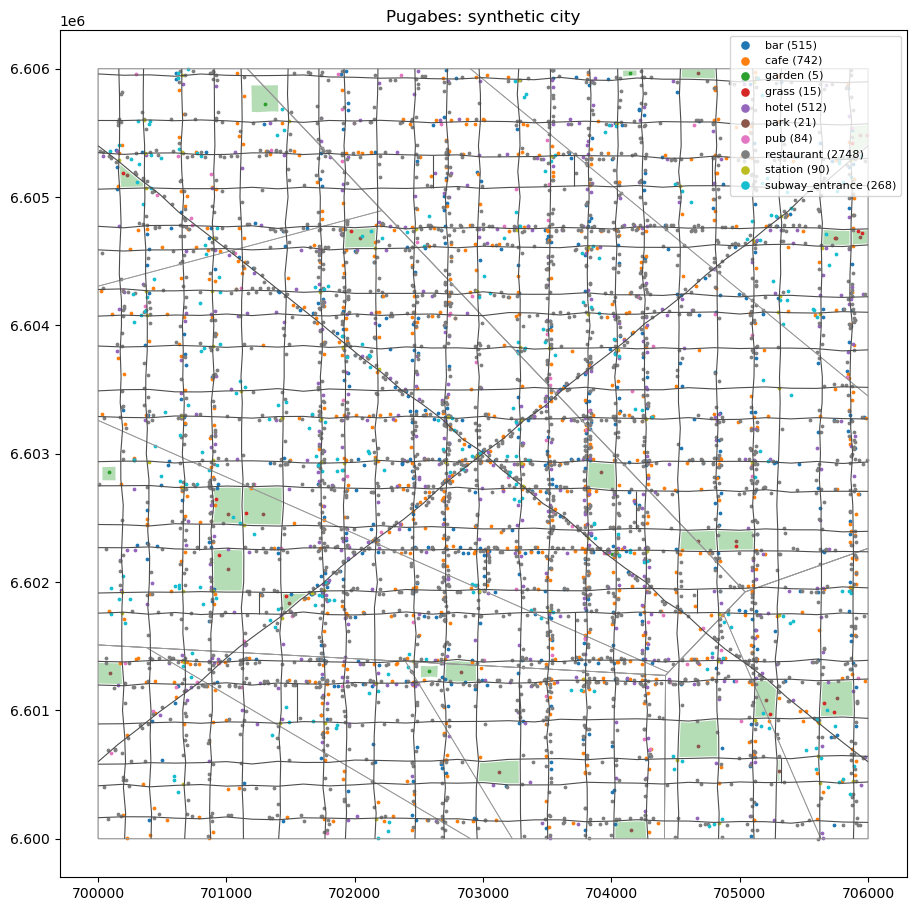

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 11))
df_area[df_area["category"] == "administrative"].boundary.plot(ax=ax, color="0.6", linewidth=0.6)
df_area[df_area["category"] != "administrative"].plot(ax=ax, color="tab:green", alpha=0.35)
df_streets.plot(ax=ax, color="0.3", linewidth=0.8)
for category, pois in df_osm.groupby("category"):
    ax.scatter(pois["x"], pois["y"], s=3, label=f"{category} ({len(pois)})")
ax.set_aspect("equal")
ax.set_title(f"{city_name}: synthetic city")
ax.legend(loc="upper right", fontsize=8, markerscale=3)
plt.show()